# 02 — How sure are we, and which differences are real?

Two tools from statistics:

- **Confidence interval** — a mean from one snapshot is an estimate; the
  interval says how far off it could plausibly be.
- **Hypothesis test** — two groups always differ a little by chance; a test
  says whether the gap is bigger than chance would produce.

With ~10,000 listings almost any gap is "statistically significant", so each
comparison also reports the gap **in euros or percentage points** — the
number that matters.

Each test is tied to a question from notebook 01: do listings asking exactly
31 nights look like those asking under or over 31, and who would the licence
phase-out reach?

**One caveat for the whole notebook.** The tests and intervals below treat
every listing as an independent observation. They are not: one host account
can run hundreds of listings (the largest 1% of accounts run 29% of
Barcelona's listings with open dates). That makes p-values and intervals too
optimistic. The effects here are large enough that the conclusions do not
hinge on them, and the last section checks the two headline gaps by
resampling whole host accounts. Notebook 03 shows how much this matters for a
smaller effect.

**Population.** Listings with open dates (the website's population), with a
usable price where a price is needed.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from src import config as cfg
from src import cleaning

sns.set_theme(style="whitegrid", palette="colorblind")
rng = np.random.default_rng(cfg.SEED)
BANDS = ["under_31", "exactly_31", "over_31"]
N_BOOT = 5000


def fmt_p(p):
    """p-values below float precision print as 0; say so instead."""
    return "< 1e-300" if p == 0 else f"{p:.2e}"

In [2]:
df = pd.read_csv(cfg.CLEAN_FILE)
df.groupby("stay_band")["price"].describe().loc[BANDS].round(1)

,count,mean,std,min,25%,50%,75%,max
stay_band,,,,,,,,
under_31,6399.0,268.0,145.7,16.0,181.0,245.0,324.0,1000.0
exactly_31,1902.0,98.9,76.5,13.0,46.0,82.5,130.0,894.0
over_31,2138.0,88.5,70.3,15.0,53.0,72.0,101.8,979.0


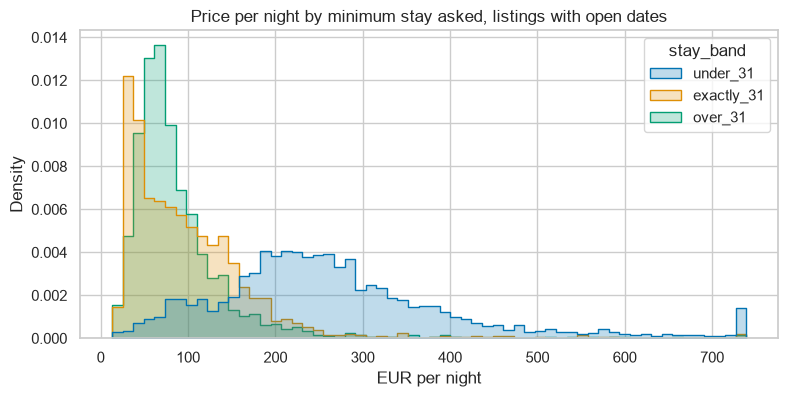

In [3]:
# One chart: price distribution per stay band (top 1% clipped so the axis is readable)
clip_at = df["price"].quantile(0.99)
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df.assign(price=df["price"].clip(upper=clip_at)),
             x="price", hue="stay_band", hue_order=BANDS,
             bins=60, element="step", stat="density", common_norm=False, ax=ax)
ax.set_xlabel("EUR per night")
ax.set_title("Price per night by minimum stay asked, listings with open dates")
fig.savefig(cfg.FIGURES_DIR / "02_price_distribution.png", dpi=150, bbox_inches="tight")

Two shapes: prices of listings asking under 31 nights spread out to the right,
while those asking exactly 31 and over 31 nights sit together at the low end. All three are right-skewed,
so the **median** is the honest "typical price"; the mean is for revenue math.

## Confidence interval for the mean price — two ways, per band

**Formula:** mean ± t · (std / √n).
**Bootstrap:** resample the data with replacement 5,000 times, take each
sample's mean, read the middle 95%. No formula, no assumptions — a good
cross-check.

In [4]:
def t_interval(values):
    """95% CI for the mean using the t formula."""
    se = values.std() / np.sqrt(len(values))
    return stats.t.interval(0.95, len(values) - 1, loc=values.mean(), scale=se)


def bootstrap_interval(values, statistic=np.mean):
    """95% CI for any statistic by resampling with replacement."""
    arr = values.to_numpy()
    boots = [statistic(rng.choice(arr, size=len(arr), replace=True)) for _ in range(N_BOOT)]
    return np.percentile(boots, [2.5, 97.5])


rows = []
for band in BANDS:
    price = df.loc[df["stay_band"] == band, "price"]
    lo_f, hi_f = t_interval(price)
    lo_b, hi_b = bootstrap_interval(price)
    rows.append({"band": band, "n": len(price), "mean": price.mean(),
                 "formula_low": lo_f, "formula_high": hi_f,
                 "boot_low": lo_b, "boot_high": hi_b})
pd.DataFrame(rows).set_index("band").round(1)

,n,mean,formula_low,formula_high,boot_low,boot_high
band,,,,,,
under_31,6399,268.0,264.4,271.5,264.5,271.6
exactly_31,1902,98.9,95.5,102.4,95.5,102.5
over_31,2138,88.5,85.6,91.5,85.6,91.7


The formula and the bootstrap agree closely in every band. The intervals
for the exactly-31 and over-31 groups are a few euros wide and sit far below
the under-31 group's.

## Test 1 — Do entire homes cost more than private rooms? (sanity check)

Listings asking under 31 nights only, so the minimum stay is comparable for both
groups.

- **H0:** the mean price is the same for both
- **Test:** two-sample t-test (Welch's version — does not assume the two
  groups have equal spread), alpha = 0.05

In [5]:
under = df[df["stay_band"] == "under_31"]
entire = under.loc[under["room_type"] == "Entire home/apt", "price"]
private = under.loc[under["room_type"] == "Private room", "price"]

t_stat, p_value = stats.ttest_ind(entire, private, equal_var=False)

print(f"entire homes  : n={len(entire):,}, mean={entire.mean():.0f} EUR")
print(f"private rooms : n={len(private):,}, mean={private.mean():.0f} EUR")
print(f"difference    : {entire.mean() - private.mean():.0f} EUR per night")
print(f"p-value       : {fmt_p(p_value)}")

entire homes  : n=4,918, mean=298 EUR
private rooms : n=1,311, mean=168 EUR
difference    : 131 EUR per night
p-value       : 2.29e-205


As expected: a large gap and a tiny p-value. If the method missed *this*,
something would be wrong.

## Test 2 — Do listings asking exactly 31 nights price like those asking under 31, or over 31?

Notebook 01 showed that listings asking exactly 31 nights almost never show an
HUT licence. If they resemble those asking over 31, their prices should be
close to the over-31 group's and far from the under-31 group's.

Two comparisons, each with a Welch t-test on the means and — because prices
are skewed — a **bootstrap CI for the difference in medians**.

In [6]:
def median_gap_interval(a, b):
    """95% bootstrap CI for median(a) - median(b)."""
    a_arr, b_arr = a.to_numpy(), b.to_numpy()
    gaps = [np.median(rng.choice(a_arr, len(a_arr))) - np.median(rng.choice(b_arr, len(b_arr)))
            for _ in range(N_BOOT)]
    return np.percentile(gaps, [2.5, 97.5])


price_of = {band: df.loc[df["stay_band"] == band, "price"] for band in BANDS}

for other in ["under_31", "over_31"]:
    a, b = price_of["exactly_31"], price_of[other]
    _, p_value = stats.ttest_ind(a, b, equal_var=False)
    lo, hi = median_gap_interval(a, b)
    print(f"exactly_31 vs {other}:")
    print(f"   mean gap   : {a.mean() - b.mean():+.0f} EUR  (p = {fmt_p(p_value)})")
    print(f"   median gap : {a.median() - b.median():+.1f} EUR, 95% CI [{lo:+.1f}, {hi:+.1f}]")

exactly_31 vs under_31:
   mean gap   : -169 EUR  (p = < 1e-300)
   median gap : -162.5 EUR, 95% CI [-167.0, -157.0]


exactly_31 vs over_31:
   mean gap   : +10 EUR  (p = 7.85e-06)
   median gap : +10.5 EUR, 95% CI [+6.0, +14.0]


Both gaps are statistically "real" — with thousands of listings, even a
few euros clear the bar. The **size** is the point: listings asking exactly 31
nights price about ten euros above those asking over 31 and over 150 euros
below those asking under 31. On price, as on licences, they look like the
over-31 group.

**What this cannot show:** whether these listings are *let* for a month.
A 31-night minimum is an asking term; the file does not record actual stays.

## Test 3 — HUT licence share: asking under 31 nights vs exactly 31

A licence is yes/no per listing, so this compares two **rates**. The right
tool is a **two-proportion z-test**, not a t-test.

Licence tests use listings with open dates, priced or not: a listing without
a price still carries a licence declaration.

In [7]:
raw = cleaning.add_columns(cleaning.load_listings())
raw = raw[raw["is_active"]]   # listings with open dates


def two_proportion_z(yes_a, n_a, yes_b, n_b):
    """z statistic and two-sided p-value for p_a - p_b."""
    p_pool = (yes_a + yes_b) / (n_a + n_b)
    se = np.sqrt(p_pool * (1 - p_pool) * (1 / n_a + 1 / n_b))
    z = (yes_a / n_a - yes_b / n_b) / se
    return z, 2 * (1 - stats.norm.cdf(abs(z)))


under_raw = raw[raw["stay_band"] == "under_31"]
exact_raw = raw[raw["stay_band"] == "exactly_31"]

z, p_value = two_proportion_z(under_raw["has_tourist_licence"].sum(), len(under_raw),
                              exact_raw["has_tourist_licence"].sum(), len(exact_raw))
print(f"asking under 31 : {under_raw['has_tourist_licence'].mean():.1%} of {len(under_raw):,} show an HUT licence")
print(f"asking exactly 31: {exact_raw['has_tourist_licence'].mean():.1%} of {len(exact_raw):,}")
print(f"difference       : {(under_raw['has_tourist_licence'].mean() - exact_raw['has_tourist_licence'].mean()) * 100:.1f} "
      f"percentage points, z = {z:.1f}, p = {fmt_p(p_value)}")

asking under 31 : 76.9% of 6,848 show an HUT licence
asking exactly 31: 0.7% of 2,293
difference       : 76.2 percentage points, z = 64.0, p = < 1e-300


A near-total split at the 31-night line. A missing HUT number is not proof of
anything illegal: a seasonal let or a room does not need one.

## Test 4 — Do the national declarations depend on the minimum stay asked?

The national code says *tourist* (`TU`) or *non-tourist* (`NT`). If hosts'
declarations matched nothing, the TU/NT split would look the same in every
group of minimum stay. A **chi-square test of independence** checks that on the
group × declaration table (listings with a readable NRUA code only).

In [8]:
coded = raw[raw["national_licence"].isin(["nrua_tourist", "nrua_seasonal"])]
table = pd.crosstab(coded["stay_band"], coded["national_licence"]).loc[BANDS]
chi2, p_value, dof, expected = stats.chi2_contingency(table)

# Cramér's V: effect size for a contingency table (0 = no link, 1 = perfect)
cramers_v = np.sqrt(chi2 / (table.to_numpy().sum() * (min(table.shape) - 1)))

print(table.to_string())
print()
print(f"chi2 = {chi2:,.0f}, dof = {dof}, p = {fmt_p(p_value)}, Cramér's V = {cramers_v:.2f}")

national_licence  nrua_seasonal  nrua_tourist
stay_band                                    
under_31                    112          4412
exactly_31                 1005            27
over_31                    1422            16

chi2 = 6,340, dof = 2, p = < 1e-300, Cramér's V = 0.95


The p-value says the link is not chance; **Cramér's V** says how strong it
is, on a 0–1 scale. A value near 1 means a host's declared use almost
perfectly predicts which side of the 31-night line the listing's minimum stay
sits on — declarations and asking terms are consistent.

**What this cannot show:** whether the declarations are *true*. Consistency
between two things a host writes is not an inspection.

## Test 5 — Who would the licence phase-out reach?

Among listings asking under 31 nights, compare the share run by host accounts
with 5+ listings: those **with** an HUT licence vs those **without** one.

In [9]:
with_hut = under_raw[under_raw["has_tourist_licence"]]
without_hut = under_raw[~under_raw["has_tourist_licence"]]

z, p_value = two_proportion_z(with_hut["is_professional"].sum(), len(with_hut),
                              without_hut["is_professional"].sum(), len(without_hut))
print(f"with HUT   : {with_hut['is_professional'].mean():.1%} of {len(with_hut):,} run by accounts with 5+ listings")
print(f"without HUT: {without_hut['is_professional'].mean():.1%} of {len(without_hut):,}")
print(f"difference : {(with_hut['is_professional'].mean() - without_hut['is_professional'].mean()) * 100:+.1f} "
      f"percentage points, z = {z:.1f}, p = {fmt_p(p_value)}")

with HUT   : 66.0% of 5,269 run by accounts with 5+ listings
without HUT: 64.5% of 1,579
difference : +1.5 percentage points, z = 1.1, p = 2.85e-01


Licensed and unlicensed listings are run by accounts of similar size: about
two thirds belong to accounts with 5+ listings in both groups, and the 1.5-point
difference is within chance. So, on this population, the phase-out does not
reach larger accounts more than smaller ones. (A first version of this
comparison counted listings with no open dates and found a gap of over 20
points; that gap came from the population, not from licences, which is why every
analysis now uses one population.) An account is not necessarily one owner or
one company, and this says nothing about whether the phase-out is a good idea. The data shows *who* is affected; judging the
trade-off (housing supply vs tourism income and jobs) needs evidence this
file does not contain.

## Do the headline gaps survive resampling whole host accounts?

Every test above treats listings as independent. Here the two headline gaps
are recomputed by resampling **host accounts** with replacement (2,000
draws), so an account that runs many listings counts as one unit. Same
point estimates; the interval is what changes.

In [10]:
def account_interval(frame, group_a, group_b, statistic, draws=2000):
    """95% interval for statistic(a, b) when whole host accounts are resampled.

    frame has one row per listing with host_id, a boolean column per group
    and whatever statistic needs; statistic gets the resampled sums."""
    sums = frame.groupby("host_id")[[group_a, group_b, f"{group_a}_hut", f"{group_b}_hut"]].sum().to_numpy()
    local = np.random.default_rng(cfg.SEED)
    values = []
    for _ in range(draws):
        total = sums[local.integers(0, len(sums), len(sums))].sum(axis=0)
        values.append(statistic(total))
    return np.percentile(values, [2.5, 97.5])


licence = raw[raw["stay_band"].isin(["under_31", "exactly_31"])].copy()
for band in ["under_31", "exactly_31"]:
    licence[band] = licence["stay_band"] == band
    licence[f"{band}_hut"] = licence[band] & licence["has_tourist_licence"]

point = (licence["under_31_hut"].sum() / licence["under_31"].sum()
         - licence["exactly_31_hut"].sum() / licence["exactly_31"].sum()) * 100
lo, hi = account_interval(licence, "under_31", "exactly_31",
                          lambda s: (s[2] / s[0] - s[3] / s[1]) * 100)
print(f"HUT licence share, under 31 minus exactly 31: {point:.1f} points")
print(f"   listing-level z-test says p {fmt_p(p_value)}; account-resampled 95% interval [{lo:.1f}, {hi:.1f}]")

# median price gap: exactly 31 vs over 31, resampling accounts
priced = df[df["stay_band"].isin(["exactly_31", "over_31"])]
by_account = {band: [g["price"].to_numpy() for _, g in priced[priced["stay_band"] == band].groupby("host_id")]
              for band in ["exactly_31", "over_31"]}
local = np.random.default_rng(cfg.SEED)
gaps = []
for _ in range(2000):
    medians = []
    for band in ["exactly_31", "over_31"]:
        groups = by_account[band]
        picks = local.integers(0, len(groups), len(groups))
        medians.append(np.median(np.concatenate([groups[i] for i in picks])))
    gaps.append(medians[0] - medians[1])
point = price_of["exactly_31"].median() - price_of["over_31"].median()
print(f"\nMedian price, exactly 31 minus over 31: {point:+.1f} EUR")
print(f"   account-resampled 95% interval [{np.percentile(gaps, 2.5):+.1f}, {np.percentile(gaps, 97.5):+.1f}]")

HUT licence share, under 31 minus exactly 31: 76.2 points
   listing-level z-test says p 2.85e-01; account-resampled 95% interval [73.4, 78.8]



Median price, exactly 31 minus over 31: +10.5 EUR
   account-resampled 95% interval [-15.0, +44.0]


The licence gap is so large that account resampling barely touches it: the
conclusion does not depend on treating listings as independent. The price gap
between listings asking exactly 31 and over 31 nights is small (about ten
euros), and once accounts are resampled its interval **includes zero**: the
listing-level "significant" result overstated the certainty. The right reading
is that the two groups price alike, not that one is ten euros dearer.

## What I found

1. **Typical prices, with uncertainty.** Median asking price per night:
   €245 for listings asking under 31 nights, €82.5 for exactly 31, €72 for
   over 31. Listing-level 95% CIs for the mean are narrow (under 31 [264,
   272], exactly 31 [96, 102], over 31 [86, 92]) and the formula and
   bootstrap agree; they are optimistic, because accounts run many listings.
2. **Entire homes cost more** — €131 more per night than private rooms among
   listings asking under 31 nights. A sanity check, not a finding.
3. **Listings asking exactly 31 nights price like those asking over 31.**
   Their median is €162.5 below the under-31 group (95% CI [−167, −157]) and
   €10.5 above the over-31 group. That €10.5 is listing-level [+6, +14], but
   once whole host accounts are resampled it is [−15, +44]: it includes
   zero.
4. **Licences split at the 31-night line.** 76.9% of listings asking under
   31 nights show an HUT licence, against 0.7% of those asking exactly 31
   (76.2 points; account-resampled 95% interval [73.4, 78.8]).
5. **Declared use matches the minimum stay.** Among listings with an NRUA
   code, declared use (TU/NT) and the minimum-stay group are almost
   perfectly linked (Cramér's V = 0.95). Consistent is not the same as
   verified.
6. **The phase-out does not reach larger accounts more than smaller ones.**
   66.0% of licensed under-31 listings belong to accounts with 5+ listings,
   against 64.5% of unlicensed ones (+1.5 points, p = 0.29). A version of
   this comparison that counted listings with no open dates found over 20
   points; that came from the population, not from licences.


**Next:** `03_price_regression.ipynb` — what drives the price once room
type, location and stay band are held fixed?